<a href="https://colab.research.google.com/github/mochamadx5/MachineLearning_11_MochamadReza/blob/main/JS08/JS08_Tugas01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [2]:
# 1. Load data
df = pd.read_csv('CC_Customer_Dataset.csv')

In [3]:
# 2. Hapus kolom identitas (tidak relevan untuk perhitungan jarak/clustering)
X = df.drop(columns=['Sl_No', 'Customer Key'])

In [4]:
# 3. Standarisasi Data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
# 4. Melatih Model Agglomerative Clustering (K=3)
model = AgglomerativeClustering(n_clusters=3)
labels = model.fit_predict(X_scaled)

In [6]:
# 5. Menghitung Evaluasi
sil_score = silhouette_score(X_scaled, labels)
dbi = davies_bouldin_score(X_scaled, labels)
print(f"Silhouette Score : {sil_score:.4f}")
print(f"Davies-Bouldin Index : {dbi:.4f}")

Silhouette Score : 0.5148
Davies-Bouldin Index : 0.6810


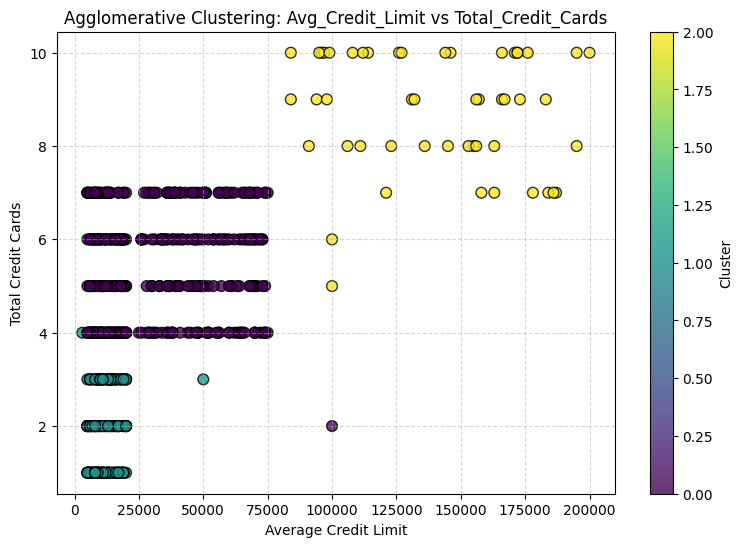

In [7]:
# 6. Scatterplot
plt.figure(figsize=(9, 6))
scatter = plt.scatter(df['Avg_Credit_Limit'], df['Total_Credit_Cards'],
                      c=labels, cmap='viridis', edgecolor='k', alpha=0.8, s=60)
plt.title('Agglomerative Clustering: Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Average Credit Limit')
plt.ylabel('Total Credit Cards')
plt.colorbar(scatter, label='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()